# Data import
What datasets are you using, later explain the variables a little bit more


In [2]:
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [3]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\combined
  school sex  age address famsize Pstatus  ...  Walc  health absences  G1  G2  G3
0     GP   F   18       U     GT3       A  ...     1       3        6   5   6   6
1     GP   F   17       U     GT3       T  ...     1       3        4   5   5   6
2     GP   F   15       U     LE3       T  ...     3       3       10   7   8  10
3     GP   F   15       U     GT3       T  ...     1       5        2  15  14  15
4     GP   F   16       U     GT3       T  ...     2       5        4   6  10  10

[5 rows x 33 columns]
  school sex  age address famsize Pstatus  ...  Walc  health absences  G1  G2  G3
0     GP   F   18       U     GT3       A  ...     1       3        4   0  11  11
1     GP   F   17       U     GT3       T  ...     1       3        2   9  11  11
2     GP   F   15       U     LE3       T  ...     3       3        6  12  13  12
3     GP   F   15       U    

In [4]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  ...          G1          G2          G3
count  395.000000  395.000000  395.000000  ...  395.000000  395.000000  395.000000
mean    16.696203    2.749367    2.521519  ...   10.908861   10.713924   10.415190
std      1.276043    1.094735    1.088201  ...    3.319195    3.761505    4.581443
min     15.000000    0.000000    0.000000  ...    3.000000    0.000000    0.000000
25%     16.000000    2.000000    2.000000  ...    8.000000    9.000000    8.000000
50%     17.000000    3.000000    2.000000  ...   11.000000   11.000000   11.000000
75%     18.000000    4.000000    3.000000  ...   13.000000   13.000000   14.000000
max     22.000000    4.000000    4.000000  ...   19.000000   19.000000   20.000000

[8 rows x 16 columns]
              age        Medu        Fedu  ...          G1          G2          G3
count  649.000000  649.000000  649.000000  ...  649.000000  649.000000  649.000000
mean    16.744222    2.514638    2.306626  ...   11.399076   11.

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [5]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [6]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Binary Classification
Predict whether G3 is above or below a threshold (e.g., 0.5)


In [7]:
# Create a binary target variable
combined_data['G3_binary'] = (combined_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary = combined_data.drop(columns=['G3', 'G3_binary'])
y_binary = combined_data['G3_binary']

In [8]:
# Split the data
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)


In [9]:
# Train Logistic Regression Model
lr_binary = LogisticRegression(max_iter=1000, random_state=42)
lr_binary.fit(X_train_binary, y_train_binary)

LogisticRegression(max_iter=1000, random_state=42)

Binary Classification Results:
Accuracy: 0.9090909090909091
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.86      0.89        87
           1       0.91      0.94      0.92       122

    accuracy                           0.91       209
   macro avg       0.91      0.90      0.91       209
weighted avg       0.91      0.91      0.91       209

Confusion Matrix:
[[ 75  12]
 [  7 115]]


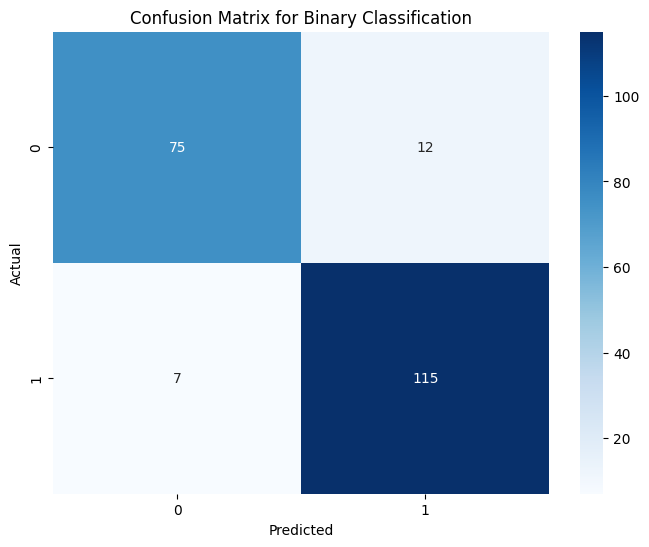

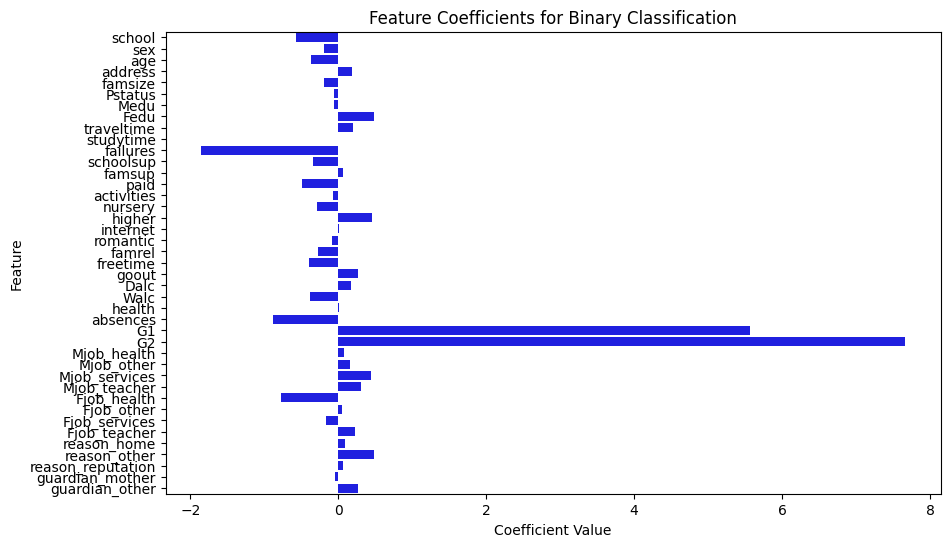

In [10]:
# Predict and evaluate
y_pred_binary = lr_binary.predict(X_test_binary)
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary)}")
print("Classification Report:")
print(classification_report(y_test_binary, y_pred_binary))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_binary))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary, y_pred_binary), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Binary Classification")
plt.show()

# Visualize coefficients
coefficients_binary = lr_binary.coef_[0]
feature_names_binary = X_binary.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=coefficients_binary, y=feature_names_binary, color="b")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for Binary Classification")
plt.show()

# 5-Level Classification
Categorize G3 into 5 performance levels

In [11]:
# Create 5 levels for the target variable (G3)
combined_data['G3_5_levels'] = pd.cut(
    combined_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [12]:
# Define features and target
X_5_levels = combined_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels = combined_data['G3_5_levels']

In [13]:
# Split the data
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X_5_levels, y_5_levels, test_size=0.2, random_state=42
)

In [14]:
# Train Logistic Regression Model
lr_5_levels = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)
lr_5_levels.fit(X_train_5, y_train_5)

c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)

5-Level Classification Results:
Accuracy: 0.6363636363636364
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.17      0.29        12
           1       0.50      0.18      0.26        28
           2       0.62      0.84      0.71        94
           3       0.69      0.72      0.70        64
           4       0.33      0.09      0.14        11

    accuracy                           0.64       209
   macro avg       0.63      0.40      0.42       209
weighted avg       0.63      0.64      0.60       209

Confusion Matrix:
[[ 2  1  9  0  0]
 [ 0  5 23  0  0]
 [ 0  4 79 11  0]
 [ 0  0 16 46  2]
 [ 0  0  0 10  1]]


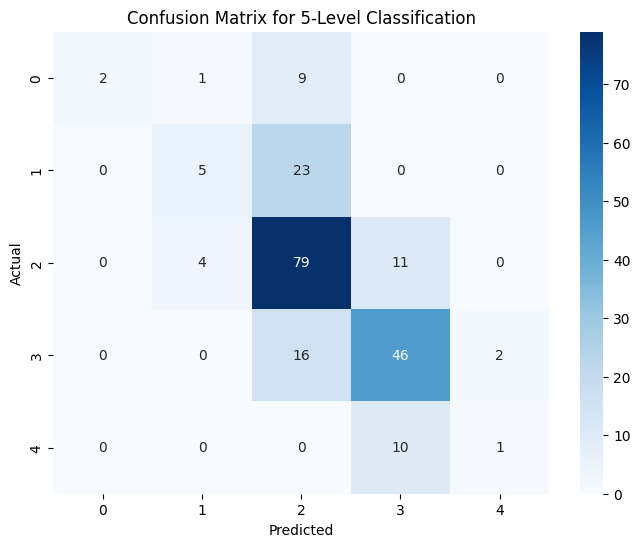

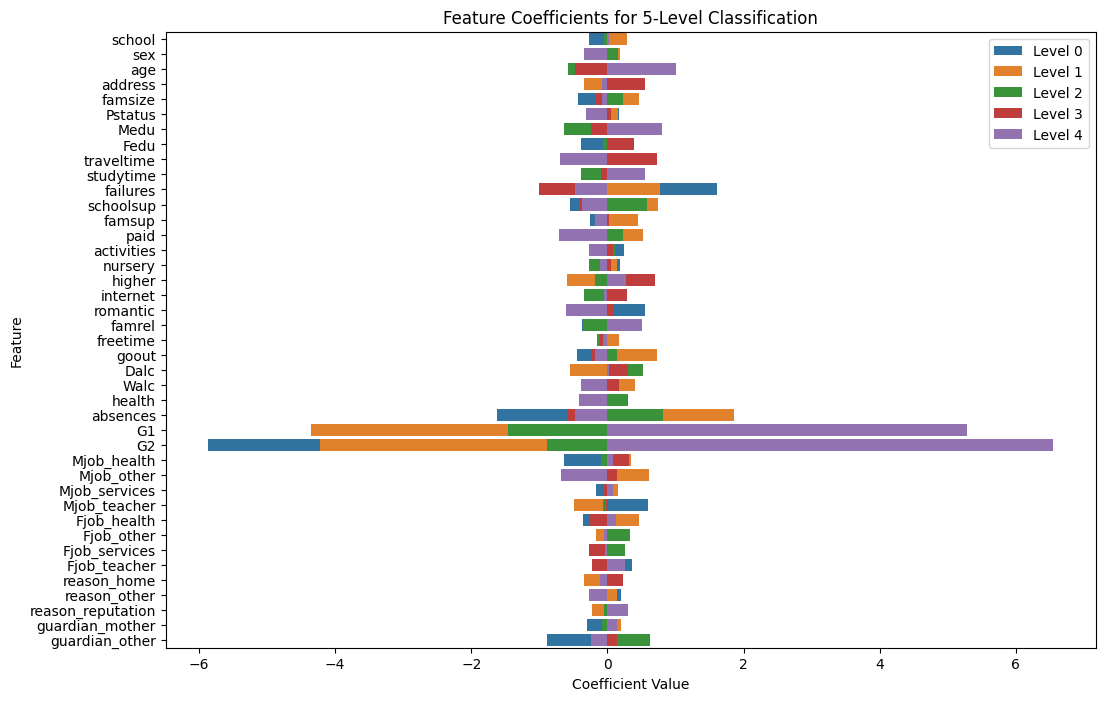

In [ ]:
# Predict and evaluate
y_pred_5 = lr_5_levels.predict(X_test_5)
print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5, y_pred_5)}")
print("Classification Report:")
print(classification_report(y_test_5, y_pred_5))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5, y_pred_5))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5, y_pred_5), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for 5-Level Classification")
plt.show()

# Visualize coefficients
coefficients_5_levels = lr_5_levels.coef_
feature_names_5_levels = X_5_levels.columns

plt.figure(figsize=(12, 8))
for i in range(coefficients_5_levels.shape[0]):
    sns.barplot(x=coefficients_5_levels[i], y=feature_names_5_levels, label=f"Level {i}")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for 5-Level Classification")
plt.legend()
plt.show()
